<a href="https://colab.research.google.com/github/2DObjectDetector/T24/blob/main/Emma_Sloan_Ass2_T24.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import matplotlib.pyplot as plt

from google.colab import drive
drive.mount('/content/drive')
!rm -rf /content/kitti3k_yolo
!cp -r /content/drive/MyDrive/kitti3k_yolo /content/kitti3k_yolo
dataset_yaml = "/content/kitti3k_yolo/kitti3k.yaml"

# install YOLO
!pip install -U ultralytics
from ultralytics import YOLO

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# locate the 3 images and their labels

image_ids = ['000136', '000232', '000189']

image_paths = [f'/content/kitti3k_yolo/images/val/{img_id}.png' for img_id in image_ids]
label_paths = [f'/content/kitti3k_yolo/labels/val/{img_id}.txt' for img_id in image_ids]

class_names = {0: 'Cyclist', 1: 'Pedestrian', 2: 'Car'}

In [ ]:
# get ground truth bounding boxes

import cv2

def load_yolo_labels(label_path, img_width, img_height):

    boxes = []
    with open(label_path) as f:
        for line in f:
            parts = line.strip().split()
            if not parts:
                continue
            cls, x_c, y_c, w, h = map(float, parts)
            cls = int(cls)
            x_c_px, w_px = x_c * img_width, w * img_width
            y_c_px, h_px = y_c * img_height, h * img_height
            x1 = x_c_px - w_px / 2
            y1 = y_c_px - h_px / 2
            x2 = x_c_px + w_px / 2
            y2 = y_c_px + h_px / 2
            boxes.append((cls, x1, y1, x2, y2))
    return boxes


gt_data = {}
for img_id, img_path, label_path in zip(image_ids, image_paths, label_paths):
    img = cv2.imread(img_path)
    h, w = img.shape[:2]
    gt_boxes = load_yolo_labels(label_path, w, h)
    gt_data[img_id] = {'image': img, 'width': w, 'height': h, 'gt_boxes': gt_boxes}
    print(f"{img_id}: {len(gt_boxes)} ground truth boxes")

000136: 6 ground truth boxes
000232: 2 ground truth boxes
000189: 5 ground truth boxes


In [ ]:
# run predictions and match against ground truth

def compute_iou(box1, box2):
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = max(0, x2 - x1) * max(0, y2 - y1)
    area1 = (box1[2] - box1[0]) * (box1[3] - box1[1])
    area2 = (box2[2] - box2[0]) * (box2[3] - box2[1])
    union = area1 + area2 - intersection

    return intersection / union if union > 0 else 0


def get_predictions(model, img_path, conf_threshold=0.25):

    results = model.predict(img_path, conf=conf_threshold, verbose=False)[0]
    preds = []
    for box in results.boxes:
        cls = int(box.cls.item())
        conf = float(box.conf.item())
        x1, y1, x2, y2 = box.xyxy[0].tolist()
        preds.append((cls, x1, y1, x2, y2, conf))
    preds.sort(key=lambda p: p[5], reverse=True)
    return preds


def match_predictions(pred_boxes, gt_boxes, iou_threshold=0.5):

    matched_gt_idx = set()
    matched_results = []

    for pred in pred_boxes:
        pred_class = pred[0]
        pred_box_coords = pred[1:5]
        best_iou = 0
        best_gt_idx = -1
        for i, gt in enumerate(gt_boxes):
            gt_class = gt[0]
            gt_box_coords = gt[1:5]
            if gt_class != pred_class or i in matched_gt_idx:
                continue
            iou = compute_iou(pred_box_coords, gt_box_coords)
            if iou > best_iou:
                best_iou = iou
                best_gt_idx = i

        if best_iou >= iou_threshold:
            matched_results.append(('TP', pred))
            matched_gt_idx.add(best_gt_idx)
        else:
            matched_results.append(('FP', pred))

    fn_boxes = [gt for i, gt in enumerate(gt_boxes) if i not in matched_gt_idx]
    return matched_results, fn_boxes


CONF_THRESHOLD = 0.25
IOU_THRESHOLD = 0.5

def analyse_image(model, img_id, conf_threshold=CONF_THRESHOLD, iou_threshold=IOU_THRESHOLD):
    data = gt_data[img_id]
    preds = get_predictions(model, image_paths[image_ids.index(img_id)], conf_threshold)
    matched_results, fn_boxes = match_predictions(preds, data['gt_boxes'], iou_threshold)
    return matched_results, fn_boxes

In [ ]:
 # plot ground truth bounding boxes and predicted bounding boxes

import matplotlib.pyplot as plt
import matplotlib.patches as patches

def plot_detection_results(img_id, matched_results, fn_boxes, title):
    data = gt_data[img_id]
    img_rgb = cv2.cvtColor(data['image'], cv2.COLOR_BGR2RGB)

    fig, ax = plt.subplots(1, figsize=(10, 8))
    ax.imshow(img_rgb)

    # ground truth in blue
    for gt in data['gt_boxes']:
        cls, x1, y1, x2, y2 = gt
        rect = patches.Rectangle((x1, y1), x2-x1, y2-y1, linewidth=2, edgecolor='blue', facecolor='none')
        ax.add_patch(rect)

    # predictions: TP green, FP red
    for label, pred in matched_results:
        cls, x1, y1, x2, y2, conf = pred
        color = 'green' if label == 'TP' else 'red'
        rect = patches.Rectangle((x1, y1), x2-x1, y2-y1, linewidth=2, edgecolor=color, facecolor='none', linestyle='--')
        ax.add_patch(rect)
        ax.text(x1, y1-5, f'{label} {conf:.2f}', color=color, fontsize=9, weight='bold')

    # false negatives: amber, drawn thicker to distinguish from GT blue box underneath
    for gt in fn_boxes:
        cls, x1, y1, x2, y2 = gt
        rect = patches.Rectangle((x1, y1), x2-x1, y2-y1, linewidth=3, edgecolor='orange', facecolor='none', linestyle=':')
        ax.add_patch(rect)
        ax.text(x1, y2+15, 'FN', color='orange', fontsize=9, weight='bold')

    ax.set_title(title)
    ax.axis('off')
    plt.tight_layout()
    plt.show()

In [ ]:
#Retrain configs 1 and 2 from t2.2

model_config1 = YOLO("yolo11n.pt")
model_config1.train(
    data=dataset_yaml, epochs=20, imgsz=640, batch=16, lr0=0.001, freeze=10,
    workers=2, cache="ram", device=0, exist_ok=True, pretrained=True,
)

model_config2 = YOLO("yolo11n.pt")
model_config2.train(
    data=dataset_yaml, epochs=40, imgsz=640, batch=16, lr0=0.001, freeze=10,
    workers=2, cache="ram", device=0, exist_ok=True, pretrained=True,
)

Ultralytics 8.4.125 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/kitti3k_yolo/kitti3k.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=False, opse

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7f4900fe2ea0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04

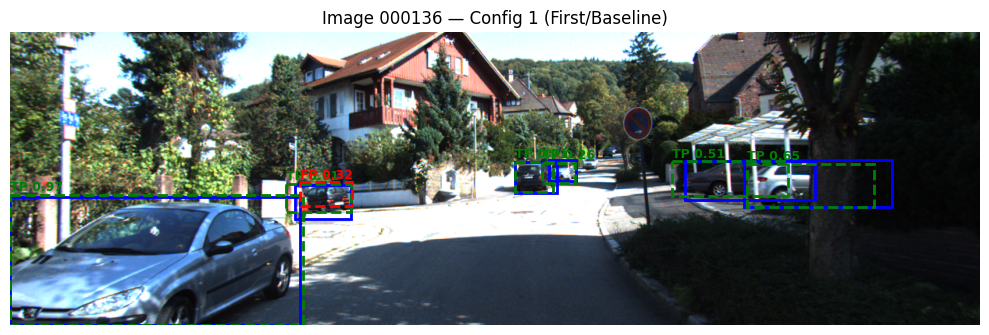

Config 1 — 000136: TP=6, FP=1, FN=0


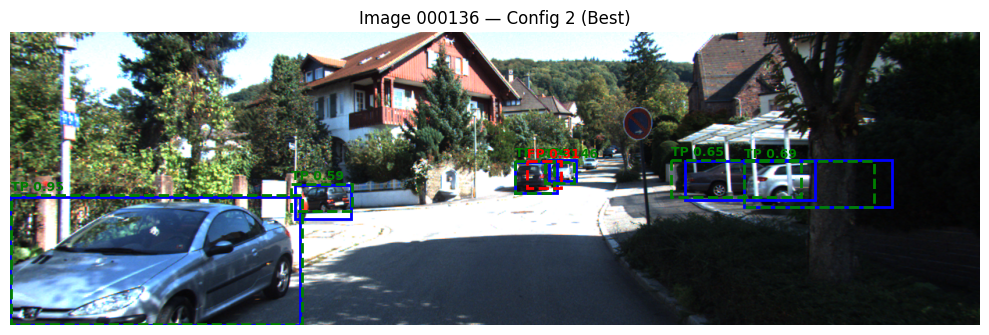

Config 2 — 000136: TP=6, FP=1, FN=0



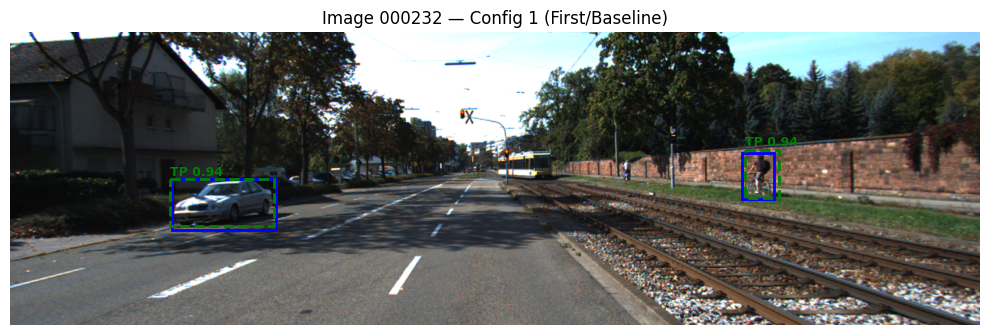

Config 1 — 000232: TP=2, FP=0, FN=0


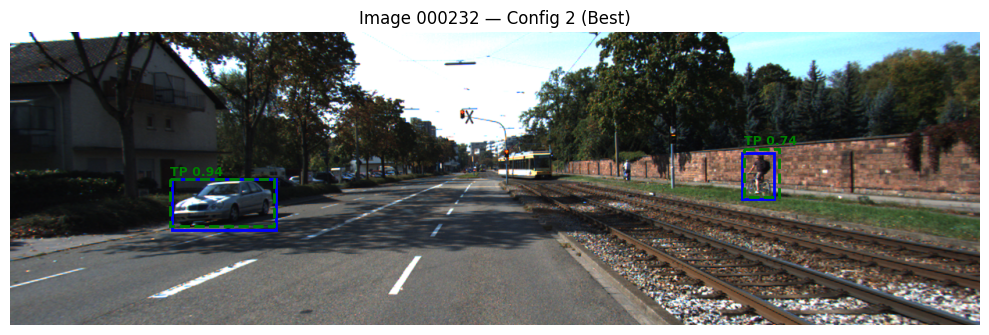

Config 2 — 000232: TP=2, FP=0, FN=0



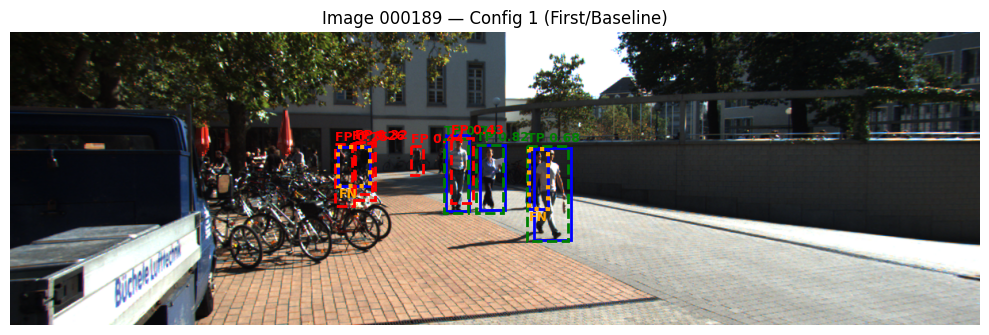

Config 1 — 000189: TP=3, FP=5, FN=2


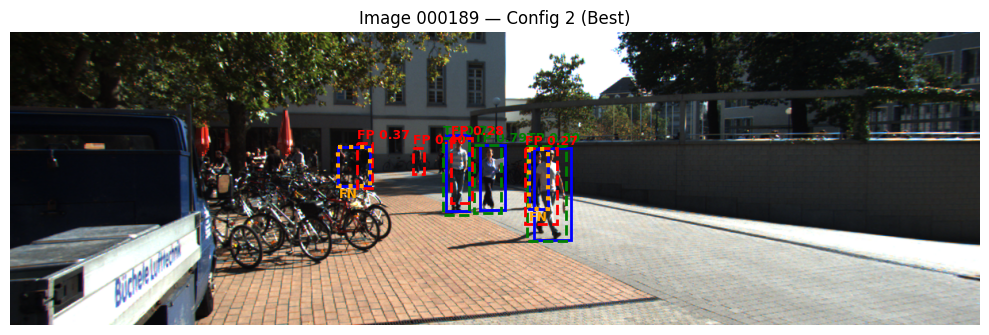

Config 2 — 000189: TP=3, FP=4, FN=2



In [ ]:

for img_id in image_ids:
    # Config 1 (first)
    matched_1, fn_1 = analyse_image(model_config1, img_id)
    plot_detection_results(img_id, matched_1, fn_1, f'Image {img_id} — Config 1 (First/Baseline)')
    tp_count = sum(1 for l, _ in matched_1 if l == 'TP')
    fp_count = sum(1 for l, _ in matched_1 if l == 'FP')
    print(f"Config 1 — {img_id}: TP={tp_count}, FP={fp_count}, FN={len(fn_1)}")

    # Config 2 (best)
    matched_2, fn_2 = analyse_image(model_config2, img_id)
    plot_detection_results(img_id, matched_2, fn_2, f'Image {img_id} — Config 2 (Best)')
    tp_count = sum(1 for l, _ in matched_2 if l == 'TP')
    fp_count = sum(1 for l, _ in matched_2 if l == 'FP')
    print(f"Config 2 — {img_id}: TP={tp_count}, FP={fp_count}, FN={len(fn_2)}")
    print()